##Cybersecurity Network Traffic Analysis.
This notebook analyses network traffic data to identify attacks and predict connection duration.

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("repeat-dataset.csv")

df.head()

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,is_attack,attack_category
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,0,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,0,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,1,dos
3,0,tcp,http,SF,232,8153,0,0,0,0,...,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,0,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,0,normal


## Data Understanding
Analysis of the data set to understand the data structure, values, and quality prior to modelling.

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25192 entries, 0 to 25191
Data columns (total 44 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   duration                     25192 non-null  int64  
 1   protocol_type                25192 non-null  object 
 2   service                      25192 non-null  object 
 3   flag                         25192 non-null  object 
 4   src_bytes                    25192 non-null  int64  
 5   dst_bytes                    25192 non-null  int64  
 6   land                         25192 non-null  int64  
 7   wrong_fragment               25192 non-null  int64  
 8   urgent                       25192 non-null  int64  
 9   hot                          25192 non-null  int64  
 10  num_failed_logins            25192 non-null  int64  
 11  logged_in                    25192 non-null  int64  
 12  num_compromised              25192 non-null  int64  
 13  root_shell      

In [18]:
df.describe()

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,is_attack
count,25192.000000,2.519200e+04,2.519200e+04,25192.000000,25192.000000,25192.00000,25192.000000,25192.000000,25192.000000,25192.000000,...,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000,25192.000000
mean,305.054104,2.433063e+04,3.491847e+03,0.000079,0.023738,0.00004,0.198039,0.001191,0.394768,0.227850,...,115.063036,0.519791,0.082539,0.147453,0.031844,0.285800,0.279846,0.117800,0.118769,0.466140
std,2686.555640,2.410805e+06,8.883072e+04,0.008910,0.260221,0.00630,2.154202,0.045418,0.488811,10.417352,...,110.646850,0.448944,0.187191,0.308367,0.110575,0.445316,0.446075,0.305869,0.317333,0.498862
min,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,10.000000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,4.400000e+01,0.000000e+00,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,61.000000,0.510000,0.030000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,2.790000e+02,5.302500e+02,0.000000,0.000000,0.00000,0.000000,0.000000,1.000000,0.000000,...,255.000000,1.000000,0.070000,0.060000,0.020000,1.000000,1.000000,0.000000,0.000000,1.000000
max,42862.000000,3.817091e+08,5.151385e+06,1.000000,3.000000,1.00000,77.000000,4.000000,1.000000,884.000000,...,255.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [19]:
df.isnull().sum()

,0
duration,0
protocol_type,0
service,0
flag,0
src_bytes,0
dst_bytes,0
land,0
wrong_fragment,0
urgent,0
hot,0


In [20]:
df.head(10)

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,is_attack,attack_category
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,0,normal
1,0,udp,other,SF,146,0,0,0,0,0,...,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,0,normal
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,1,dos
3,0,tcp,http,SF,232,8153,0,0,0,0,...,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,0,normal
4,0,tcp,http,SF,199,420,0,0,0,0,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,0,normal
5,0,tcp,private,REJ,0,0,0,0,0,0,...,0.07,0.00,0.00,0.00,0.00,1.00,1.00,neptune,1,dos
6,0,tcp,private,S0,0,0,0,0,0,0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,1,dos
7,0,tcp,private,S0,0,0,0,0,0,0,...,0.07,0.00,0.00,1.00,1.00,0.00,0.00,neptune,1,dos
8,0,tcp,remote_job,S0,0,0,0,0,0,0,...,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,1,dos
9,0,tcp,private,S0,0,0,0,0,0,0,...,0.06,0.00,0.00,1.00,1.00,0.00,0.00,neptune,1,dos


## Exploratory Data Analysis
Graphs are utilized for exploration of normal and abnormal traffic, attacks types, protocols and services.

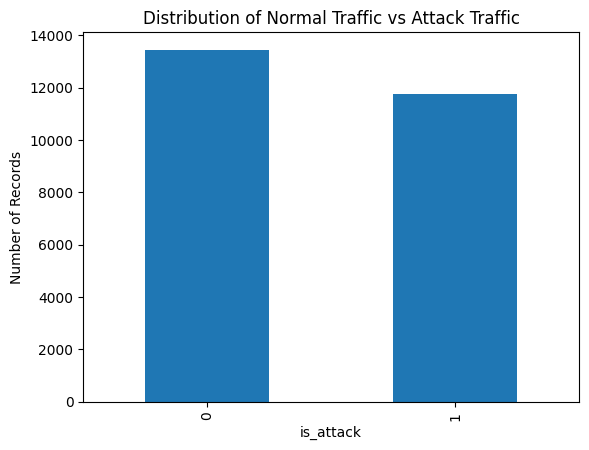

In [21]:
import matplotlib.pyplot as plt

df['is_attack'].value_counts().plot(kind='bar')

plt.title('Distribution of Normal Traffic vs Attack Traffic')
plt.xlabel('is_attack')
plt.ylabel('Number of Records')

plt.show()

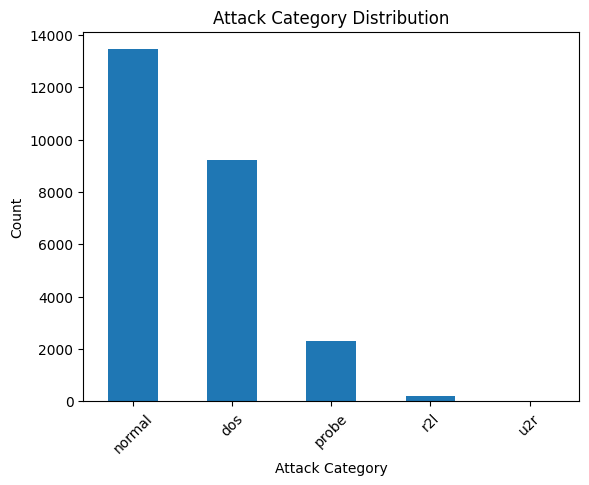

In [22]:
df['attack_category'].value_counts().plot(kind='bar')

plt.title('Attack Category Distribution')
plt.xlabel('Attack Category')
plt.ylabel('Count')

plt.xticks(rotation=45)

plt.show()

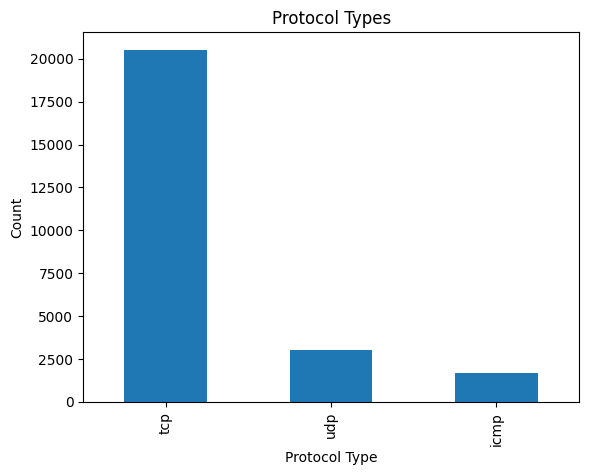

In [23]:
df['protocol_type'].value_counts().plot(kind='bar')

plt.title('Protocol Types')
plt.xlabel('Protocol Type')
plt.ylabel('Count')

plt.show()

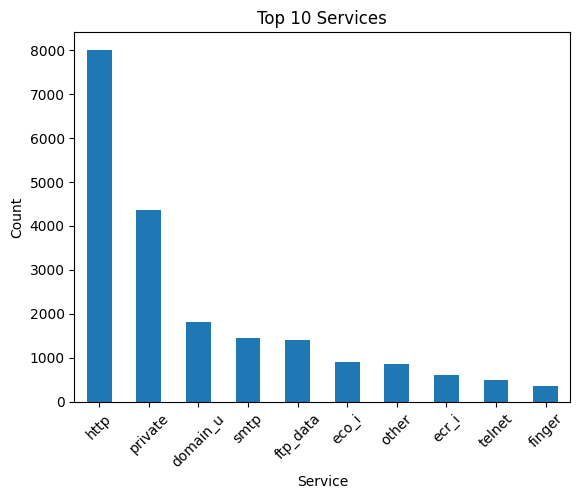

In [24]:
df['service'].value_counts().head(10).plot(kind='bar')

plt.title('Top 10 Services')
plt.xlabel('Service')
plt.ylabel('Count')

plt.xticks(rotation=45)

plt.show()

## Correlation Analysis
Correlation heatmap is utilized to analyze the relationship between numeric variables.

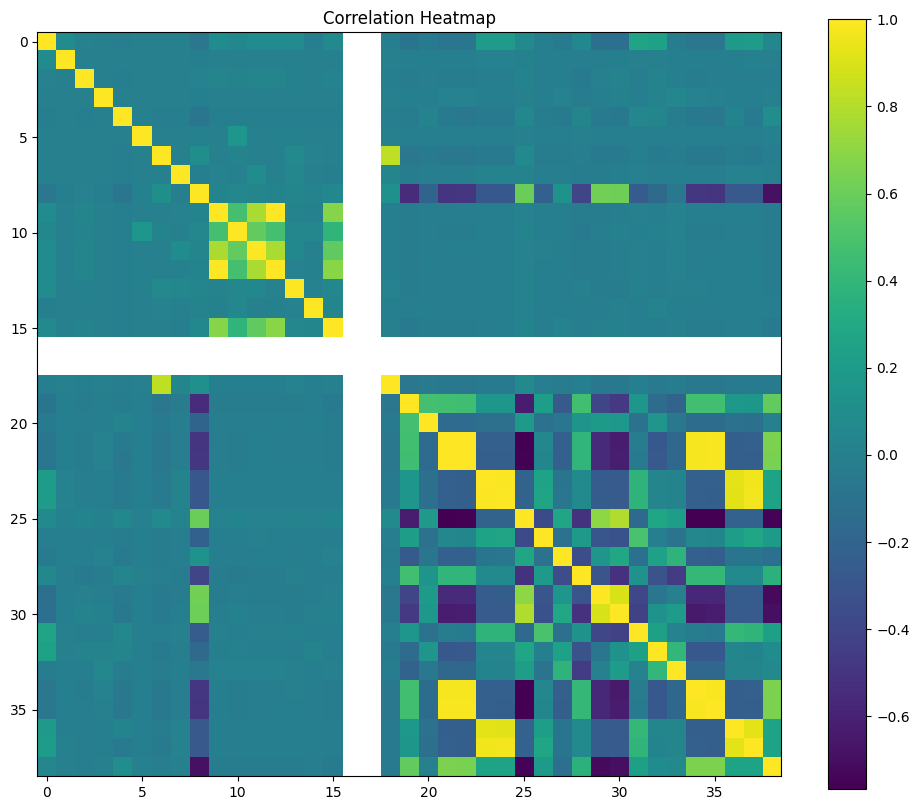

In [25]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12,10))
plt.imshow(correlation)

plt.colorbar()

plt.title("Correlation Heatmap")

plt.show()

In [26]:
df.shape

(25192, 44)

In [27]:
df.duplicated().sum()

np.int64(0)

In [28]:
df['is_attack'].value_counts()

,count
is_attack,
0,13449
1,11743


In [29]:
df['attack_category'].value_counts()

,count
attack_category,
normal,13449
dos,9234
probe,2289
r2l,209
u2r,11


In [30]:
df[['protocol_type', 'service', 'flag']].head()

,protocol_type,service,flag
0,tcp,ftp_data,SF
1,udp,other,SF
2,tcp,private,S0
3,tcp,http,SF
4,tcp,http,SF


In [31]:
df.columns

Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
       'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
       'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
       'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate', 'label', 'is_attack', 'attack_category'],
      dtype='object')

## Data Preparation
Data is transformed to create new features and to change categorical data to numeric.

In [32]:
df['total_bytes'] = df['src_bytes'] + df['dst_bytes']

df[['src_bytes', 'dst_bytes', 'total_bytes']].head()

,src_bytes,dst_bytes,total_bytes
0,491,0,491
1,146,0,146
2,0,0,0
3,232,8153,8385
4,199,420,619


In [33]:
df['byte_difference'] = abs(df['src_bytes'] - df['dst_bytes'])

df[['src_bytes', 'dst_bytes', 'byte_difference']].head()

,src_bytes,dst_bytes,byte_difference
0,491,0,491
1,146,0,146
2,0,0,0
3,232,8153,7921
4,199,420,221


In [34]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df['protocol_type'] = le.fit_transform(df['protocol_type'])
df['service'] = le.fit_transform(df['service'])
df['flag'] = le.fit_transform(df['flag'])

df[['protocol_type', 'service', 'flag']].head()

,protocol_type,service,flag
0,1,19,9
1,2,41,9
2,1,46,5
3,1,22,9
4,1,22,9


## Classification Setup
The is_attack is chosen as the target variable, and the dataset is split into training and test datasets.

In [35]:
X = df.drop(['is_attack', 'label', 'attack_category', 'duration'], axis=1)

y = df['is_attack']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (25192, 42)
Target shape: (25192,)


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (20153, 42)
Testing data: (5039, 42)


## Decision Tree Classification
A Decision Tree is developed for the classification of traffic into normal or malicious, and its performance is assessed.

In [37]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [38]:
y_pred_dt = dt_model.predict(X_test)

print(y_pred_dt[:10])

[1 0 1 0 1 0 0 0 0 1]


In [39]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

dt_accuracy = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", dt_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 0.9958325064496923

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      2674
           1       0.99      1.00      1.00      2365

    accuracy                           1.00      5039
   macro avg       1.00      1.00      1.00      5039
weighted avg       1.00      1.00      1.00      5039



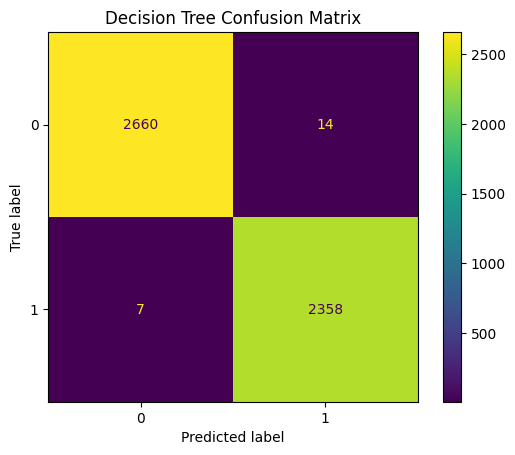

In [40]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt)

plt.title("Decision Tree Confusion Matrix")
plt.show()

## Random Forest Classifier
The Random Forest classifier is built and tested for the purpose of comparing its performance with that of the Decision Tree.

In [41]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [42]:
y_pred_rf = rf_model.predict(X_test)

print(y_pred_rf[:10])

[1 0 1 0 1 0 0 0 0 1]


In [43]:
from sklearn.metrics import accuracy_score, classification_report

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 0.9980154792617583

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2674
           1       1.00      1.00      1.00      2365

    accuracy                           1.00      5039
   macro avg       1.00      1.00      1.00      5039
weighted avg       1.00      1.00      1.00      5039



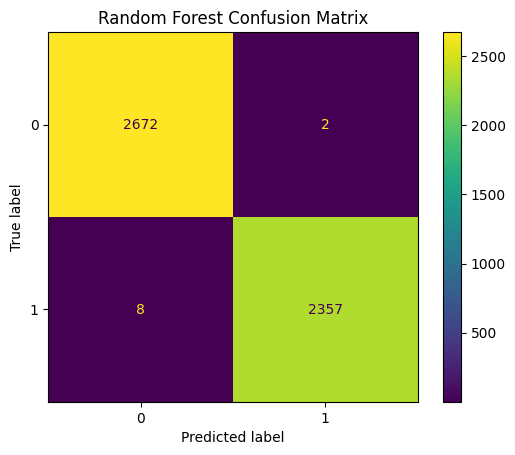

In [44]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf)

plt.title("Random Forest Confusion Matrix")
plt.show()

## Regression Analysis Setup
The connection duration has been chosen as the numeric dependent variable for regression analysis.

In [45]:
X_reg = df.drop(columns=['duration', 'label', 'attack_category'])

y_reg = df['duration']

print("Features:", X_reg.shape)
print("Target:", y_reg.shape)

Features: (25192, 43)
Target: (25192,)


In [46]:
from sklearn.model_selection import train_test_split

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train_reg.shape)
print("Testing data:", X_test_reg.shape)

Training data: (20153, 43)
Testing data: (5039, 43)


## Random Forest Regression
The random forest regressor predicts the duration with MAE, MSE, and R² used for its evaluation.


In [47]:
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(random_state=42)

rf_reg.fit(X_train_reg, y_train_reg)

print("Regression model trained successfully!")

Regression model trained successfully!


In [48]:
y_pred_reg = rf_reg.predict(X_test_reg)

print(y_pred_reg[:10])

[0.   0.   0.   0.72 0.64 0.   1.41 1.28 0.   0.  ]


In [49]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)

print("MAE:", mae)
print("MSE:", mse)
print("R² Score:", r2)

MAE: 99.44354795915011
MSE: 670560.9244498386
R² Score: 0.8760327641631911


## Decision Tree Regression
Performance of the Decision Tree Regressor is measured by the same criteria to enable comparison between the regression models.

In [50]:
from sklearn.tree import DecisionTreeRegressor

dt_reg = DecisionTreeRegressor(random_state=42)

dt_reg.fit(X_train_reg, y_train_reg)

print("Decision Tree Regression model trained successfully!")

Decision Tree Regression model trained successfully!


In [51]:
y_pred_dt_reg = dt_reg.predict(X_test_reg)

print(y_pred_dt_reg[:10])

[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

dt_reg_mae = mean_absolute_error(y_test_reg, y_pred_dt_reg)
dt_reg_mse = mean_squared_error(y_test_reg, y_pred_dt_reg)
dt_reg_r2 = r2_score(y_test_reg, y_pred_dt_reg)

print("Decision Tree Regression MAE:", dt_reg_mae)
print("Decision Tree Regression MSE:", dt_reg_mse)
print("Decision Tree Regression R²:", dt_reg_r2)

Decision Tree Regression MAE: 101.97387695120902
Decision Tree Regression MSE: 836494.3353449471
Decision Tree Regression R²: 0.8453564966808338


In [53]:
import pandas as pd

regression_comparison = pd.DataFrame({
    'Model': ['Decision Tree Regressor', 'Random Forest Regressor'],
    'MAE': [dt_reg_mae, mae],
    'MSE': [dt_reg_mse, mse],
    'R²': [dt_reg_r2, r2]
})

regression_comparison

,Model,MAE,MSE,R²
0,Decision Tree Regressor,101.973877,836494.335345,0.845356
1,Random Forest Regressor,99.443548,670560.924450,0.876033


## Cross Validation
Cross validation is done using five fold cross validation to compare the classification algorithms.

In [54]:
from sklearn.model_selection import cross_val_score

dt_cv_scores = cross_val_score(dt_model, X, y, cv=5, scoring='accuracy')
rf_cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='accuracy')

print("Decision Tree CV Mean Accuracy:", dt_cv_scores.mean())
print("Random Forest CV Mean Accuracy:", rf_cv_scores.mean())

Decision Tree CV Mean Accuracy: 0.9961098981733665
Random Forest CV Mean Accuracy: 0.9974594904484994


In [55]:
classification_comparison = pd.DataFrame({
    'Model': ['Decision Tree', 'Random Forest'],
    'Hold-out Accuracy': [dt_accuracy, rf_accuracy],
    'Cross-validation Accuracy': [dt_cv_scores.mean(), rf_cv_scores.mean()]
})

classification_comparison

,Model,Hold-out Accuracy,Cross-validation Accuracy
0,Decision Tree,0.995833,0.996110
1,Random Forest,0.998015,0.997459
